# 02 · Narrowness and fatigue

In notebook 01 the broadest and the narrowest users both watched less of each video. That was a comparison *between* people, so it could just mean those people are different. Here I ask the question that matters for a product decision.

**When the same user's recent feed gets narrower, do they watch less and leave sooner?**

Plan
1. Split every user's log into sessions (a 30 minute gap starts a new one)
2. For every view, compute the Narrowness Index of the 20 videos watched just before it
3. Regress watch ratio on narrowness with user fixed effects (compares a user to themselves) and video fixed effects (removes the fact that some videos are just better)
4. Do the same for the chance that the session ends after this video
5. Check the result holds for other window sizes and on a separate group of users
6. Separate two things that sound alike: a narrow *mix* of content versus long *runs* of the same tag in a row
7. Step back from the session to the next day. Does a narrow day predict a user coming back less?

In [1]:
import sys, json, re, gc
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.features import build, OUT
from src.fe import feols
from src.daily import user_day_panel

FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY = "#3b6ea8", "#c0392b", "#8a8a8a"

# Each regression is cached so a long run can be resumed. Delete data/cache to recompute.
CACHE = ROOT / "data" / "cache"; CACHE.mkdir(exist_ok=True)
def cfeols(key, *args, **kw):
    p = CACHE / (re.sub(r"[^A-Za-z0-9_]+", "_", key) + ".pkl")
    if p.exists():
        res, attrs = pd.read_pickle(p)
        res.attrs.update(attrs)
        return res
    res = feols(*args, **kw)
    pd.to_pickle((res, dict(res.attrs)), p)
    return res

## 1. Build the features

`src/features.py` processes users in chunks. For each view it records the session, the position in the session, whether the session ended right after it, and the rolling features.

- `narrow_N`. Narrowness of the previous N videos (N = 10, 20, 50). Each video splits a weight of 1 across its tags.
- `repeat_share`. Share of the previous 20 videos' tag weight that lands on the current video's tags. High means "more of the same".
- `streak`. How many videos in a row just before this one had the same main tag.

In [2]:
if not OUT.exists():
    build()
# The full table is 12.5M rows. To stay inside a few GB of RAM every step reads only the columns it needs.
read = lambda cols, **kw: pd.read_parquet(OUT, columns=cols, **kw)
f = read(["user_id", "session_id", "sess_len", "exit", "narrow_20", "day"])
totals = {"views": len(f), "users": f.user_id.nunique(), "sessions": f.session_id.nunique()}
print(f"{totals['views']:,} views, {totals['users']:,} users, {totals['sessions']:,} sessions")

12,530,806 views, 7,176 users, 101,740 sessions


## 2. Sessions

In [3]:
s = f.groupby("session_id").agg(len_=("sess_len", "first"), user=("user_id", "first"))
print(s.len_.describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())
print(f"\nSessions per user, median: {s.groupby('user').size().median():.0f}")
print(f"Share of views that end a session: {f.exit.mean():.1%}")

count    101740.0
mean         14.5
std          34.9
min           1.0
25%           2.0
50%           4.0
75%          12.0
90%          34.0
max         798.0

Sessions per user, median: 124
Share of views that end a session: 7.1%


## 3. Does narrowness actually move within a user?

Fixed effects only use variation inside each user. If a user's narrowness barely changes over time there is nothing to learn from, so I check that first.

count    1.238729e+07
mean     3.720000e-01
std      8.100000e-02
min      1.470000e-01
10%      2.870000e-01
25%      3.190000e-01
50%      3.610000e-01
75%      4.120000e-01
90%      4.680000e-01
max      1.000000e+00

Share of variance that is within user: 82%


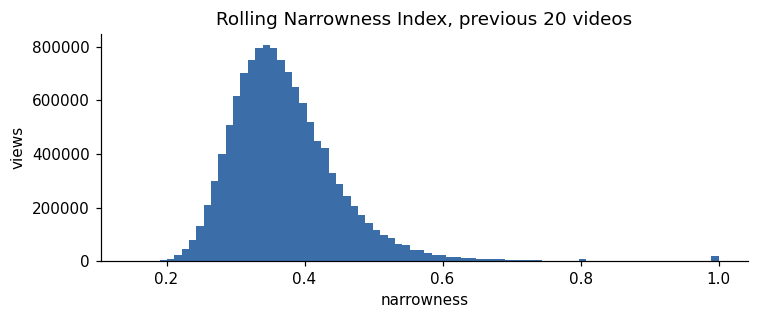

In [4]:
n20 = f.narrow_20
total_var = n20.var()
within_var = (n20 - n20.groupby(f.user_id).transform("mean")).var()
print(n20.describe(percentiles=[.1, .25, .5, .75, .9]).round(3).to_string())
print(f"\nShare of variance that is within user: {within_var / total_var:.0%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(n20.dropna(), bins=80, color=BLUE)
ax.set(title="Rolling Narrowness Index, previous 20 videos", xlabel="narrowness", ylabel="views")
fig.tight_layout(); fig.savefig(FIG / "02_rolling_narrowness.png")

With 20 videos and 31 tags the lowest possible value is about 0.13, because 20 videos can cover at most 20 tags. So the scale only means something relative to the other windows of the same size.

## 4. Estimation sample

The regressions run on 12 million rows with thousands of fixed effects, so I split users at random into three groups of about 2,400 each. Group A is the main estimate. Group B is a replication I only look at after A is done. This also means the result is not tuned on the same users it is reported on.

In [5]:
rng = np.random.default_rng(42)
users = np.sort(f.user_id.unique())
fold = pd.Series(rng.integers(0, 3, len(users)), index=users)

_, bins = pd.qcut(f.narrow_20, 10, retbins=True)          # decile cut points on the pooled distribution
edges = pd.DataFrame({"min": bins[:-1], "max": bins[1:]}).round(3)
day_mean = f.day.mean()
del f, s, n20; gc.collect()

COLS = ["user_id", "video_id", "exit", "last_sess", "wr", "full", "log_pos", "hour_block", "day",
        "streak", "repeat_share", "narrow_10", "narrow_20", "narrow_50"]
load_fold = lambda k: read(COLS, filters=[("user_id", "in", fold.index[fold == k].tolist())])
A = load_fold(0)          # group B is loaded later, after A is released

DEC = [f"d{d}" for d in range(1, 10)]
CTRL = ["log_pos", "day_c"] + [f"h{h}" for h in range(1, 6)]

def add_design(d, xcol="narrow_20", cut=None):
    # Decile dummies of xcol (cut points from the pooled data when given) plus controls, in place
    dec = (pd.cut(d[xcol], cut, labels=False, include_lowest=True) if cut is not None
           else pd.qcut(d[xcol], 10, labels=False))
    for k in range(1, 10):
        d[f"d{k}"] = (dec == k).astype("float32").where(dec.notna())
    for h in range(1, 6):
        d[f"h{h}"] = (d.hour_block == h).astype("float32")
    d["day_c"] = (d.day - day_mean).astype("float32")
    d["exit_y"] = d.exit.astype("float32").where(d.last_sess == 0)   # final session is censored

bins[0], bins[-1] = -np.inf, np.inf
add_design(A, cut=bins)
print(f"Group A: {A.user_id.nunique():,} users, {len(A):,} views")
print(f"Group B: {(fold == 1).sum():,} users")
print("\nDecile edges of narrow_20"); print(edges.T.to_string())

Group A: 2,452 users, 4,325,134 views
Group B: 2,367 users

Decile edges of narrow_20
         0      1      2      3      4      5      6      7      8      9
min  0.147  0.287  0.309  0.327  0.344  0.361  0.378  0.399  0.426  0.468
max  0.287  0.309  0.327  0.344  0.361  0.378  0.399  0.426  0.468  1.000


Controls
- `log_pos`. Position in the session. People drift off as sessions get long, whatever they are watching.
- `day_c`. Linear time trend across the two months.
- `h1`–`h5`. Four hour blocks of the day, Beijing time.

## 5. The fatigue curve

In [6]:
def curve(res, ref_label="D1 (broadest)"):
    c = res.loc[DEC, ["coef", "lo", "hi"]].copy()
    c.loc["d0"] = 0.0
    c = c.loc[["d0"] + DEC]
    c.index = range(1, 11)
    return c

r_wr = cfeols("wr_A", A, "wr", DEC + CTRL)
cw = curve(r_wr)
print(f"Mean watch ratio in sample: {r_wr.attrs['y_mean']:.3f}   n = {r_wr.attrs['n']:,}   users = {r_wr.attrs['clusters']:,}")
print((cw * 1).round(4).to_string())

Mean watch ratio in sample: 0.891   n = 4,276,094   users = 2,452
      coef      lo      hi
1   0.0000  0.0000  0.0000
2   0.0052  0.0016  0.0088
3   0.0055  0.0017  0.0094
4   0.0082  0.0042  0.0121
5   0.0099  0.0057  0.0142
6   0.0103  0.0062  0.0145
7   0.0137  0.0094  0.0181
8   0.0134  0.0088  0.0180
9   0.0167  0.0115  0.0219
10  0.0255  0.0163  0.0346


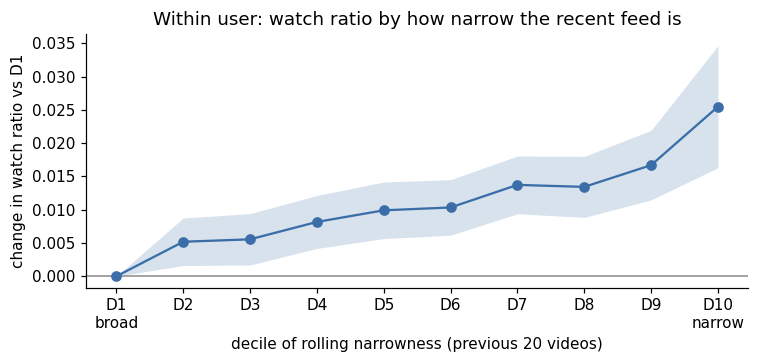

In [7]:
def plot_curve(c, ylabel, title, fname, color=BLUE):
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.axhline(0, color=GREY, lw=1)
    ax.fill_between(c.index, c.lo, c.hi, color=color, alpha=.2, lw=0)
    ax.plot(c.index, c.coef, "o-", color=color)
    ax.set_xticks(range(1, 11), ["D1\nbroad"] + [f"D{i}" for i in range(2, 10)] + ["D10\nnarrow"])
    ax.set(title=title, ylabel=ylabel, xlabel="decile of rolling narrowness (previous 20 videos)")
    fig.tight_layout(); fig.savefig(FIG / fname)
    return fig

plot_curve(cw, "change in watch ratio vs D1", "Within user: watch ratio by how narrow the recent feed is",
           "02_fatigue_curve_wr.png");

In [8]:
r_full = cfeols("full_A", A, "full", DEC + CTRL)
cf = curve(r_full)
print(f"Base rate of watching fully: {r_full.attrs['y_mean']:.1%}")
print((cf * 100).round(2).rename(columns=lambda s: s + " (pp)").to_string())

Base rate of watching fully: 33.9%
    coef (pp)  lo (pp)  hi (pp)
1        0.00     0.00     0.00
2        0.28     0.08     0.49
3        0.47     0.25     0.69
4        0.48     0.25     0.71
5        0.54     0.30     0.77
6        0.59     0.35     0.84
7        0.75     0.50     0.99
8        0.80     0.54     1.07
9        0.90     0.60     1.19
10       1.26     0.78     1.73


## 6. Do people leave sooner?

`exit` = 1 when the session ends after this video. I drop each user's final session because we cannot see whether they would have kept going after the data stops.

Base exit rate per view: 6.90%
    coef (pp)  lo (pp)  hi (pp)
1       0.000    0.000    0.000
2      -0.304   -0.413   -0.194
3      -0.292   -0.402   -0.181
4      -0.324   -0.434   -0.214
5      -0.407   -0.520   -0.295
6      -0.532   -0.644   -0.420
7      -0.520   -0.634   -0.405
8      -0.706   -0.819   -0.593
9      -0.866   -0.984   -0.748
10     -1.143   -1.280   -1.006


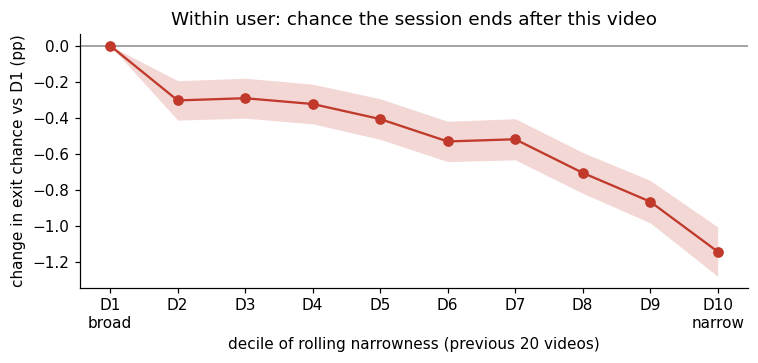

In [9]:
r_exit = cfeols("exit_A", A, "exit_y", DEC + CTRL)
ce = curve(r_exit)
print(f"Base exit rate per view: {r_exit.attrs['y_mean']:.2%}")
print((ce * 100).round(3).rename(columns=lambda s: s + " (pp)").to_string())
plot_curve(ce * 100, "change in exit chance vs D1 (pp)", "Within user: chance the session ends after this video",
           "02_fatigue_curve_exit.png", color=RED);

## 7. Narrow mix vs long runs of the same thing

A narrow window and a repetitive feed are not the same. Twenty videos split across three tags is narrow but can still alternate. Six cooking videos in a row is a run. I put the run length (`streak`, how many videos straight before this one shared its main tag) in the same model as narrowness, using bins because the effect need not be linear.

In [10]:
print("Share of views by streak length")
print(A.streak.clip(upper=10).value_counts(normalize=True).sort_index().round(4).to_string())
share_ge4 = float((A.streak >= 4).mean())
print(f"Views after a run of 4+: {share_ge4:.2%}")

A["nar"] = A.narrow_20
SB = []
for k, (lo, hi) in {"k1": (1, 1), "k2": (2, 2), "k3": (3, 3), "k4_5": (4, 5), "k6_9": (6, 9), "k10p": (10, 10_000)}.items():
    A[k] = A.streak.between(lo, hi).astype("float32"); SB.append(k)
r_st_wr = cfeols("streak_wr_A", A, "wr", SB + ["nar"] + CTRL)
r_st_ex = cfeols("streak_exit_A", A, "exit_y", SB + ["nar"] + CTRL)
st = pd.concat({"watch ratio": r_st_wr.loc[SB + ["nar"], ["coef", "lo", "hi", "p"]],
                "exit": r_st_ex.loc[SB + ["nar"], ["coef", "lo", "hi", "p"]]}, axis=1)
print(); print(st.round(4).to_string())

Share of views by streak length
streak
0     0.8022
1     0.1499
2     0.0232
3     0.0117
4     0.0031
5     0.0022
6     0.0008
7     0.0007
8     0.0004
9     0.0003
10    0.0056
Views after a run of 4+: 1.31%



     watch ratio                            exit                        
            coef      lo      hi       p    coef      lo      hi       p
k1        0.0044  0.0006  0.0081  0.0219  0.0136  0.0128  0.0145  0.0000
k2       -0.0056 -0.0127  0.0014  0.1167 -0.0081 -0.0102 -0.0059  0.0000
k3        0.0040 -0.0062  0.0142  0.4433  0.0197  0.0172  0.0222  0.0000
k4_5     -0.0234 -0.0443 -0.0025  0.0286  0.0001 -0.0032  0.0035  0.9315
k6_9     -0.0974 -0.1523 -0.0425  0.0005 -0.0062 -0.0116 -0.0007  0.0275
k10p      0.0966 -0.1222  0.3155  0.3867  0.0137  0.0058  0.0217  0.0007
nar       0.1108  0.0761  0.1455  0.0000 -0.0477 -0.0527 -0.0428  0.0000


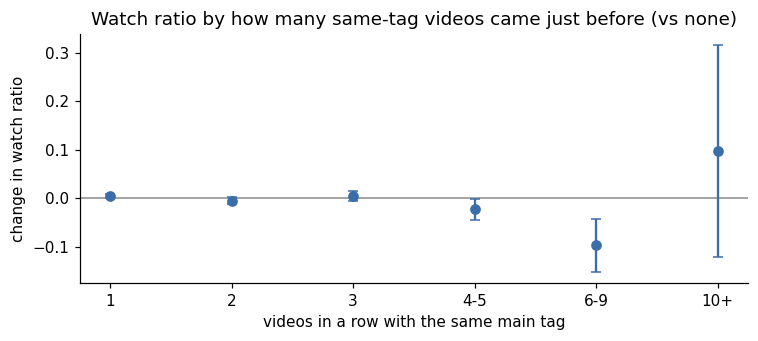

In [11]:
lab = ["1", "2", "3", "4-5", "6-9", "10+"]
c = r_st_wr.loc[SB]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axhline(0, color=GREY, lw=1)
ax.errorbar(range(len(SB)), c.coef, yerr=[c.coef - c.lo, c.hi - c.coef], fmt="o", color=BLUE, capsize=3)
ax.set_xticks(range(len(SB)), lab)
ax.set(title="Watch ratio by how many same-tag videos came just before (vs none)",
       xlabel="videos in a row with the same main tag", ylabel="change in watch ratio")
fig.tight_layout(); fig.savefig(FIG / "02_streak_effect.png")

Runs of 10 or more are mostly a handful of users looping one kind of content, so that bin is noisy. The bins that matter are 4–5 and 6–9.

## 8. Robustness

In [12]:
rows = []
def summarise(name, d, ycol, xcol="narrow_20"):
    # Window 10 and 50 have their own scale, so they get their own deciles
    add_design(d, xcol=xcol, cut=None if xcol != "narrow_20" else bins)
    r = cfeols(f"rob_{name}_{ycol}_{xcol}", d, ycol, DEC + CTRL)
    c = curve(r)
    top = c.coef.idxmax()
    rows.append({"check": name, "y": ycol, "peak decile": top,
                 "D10 vs peak": c.coef.iloc[-1] - c.coef.max(),
                 "D10 ci": f"[{c.lo.iloc[-1]:.3f}, {c.hi.iloc[-1]:.3f}]"})
    return c

curves = {"A, N=20": cw}
curves["A, N=10"] = summarise("window 10", A, "wr", "narrow_10")
curves["A, N=50"] = summarise("window 50", A, "wr", "narrow_50")
del A; gc.collect()
B = load_fold(1)
curves["B, N=20"] = summarise("replication group B", B, "wr")
summarise("replication group B", B, "exit_y")
del B; gc.collect()
rob = pd.DataFrame(rows)
print(rob.round(4).to_string(index=False))

              check      y  peak decile  D10 vs peak           D10 ci
          window 10     wr           10       0.0000   [0.008, 0.027]
          window 50     wr           10       0.0000   [0.027, 0.048]
replication group B     wr           10       0.0000   [0.018, 0.034]
replication group B exit_y            1      -0.0115 [-0.013, -0.010]


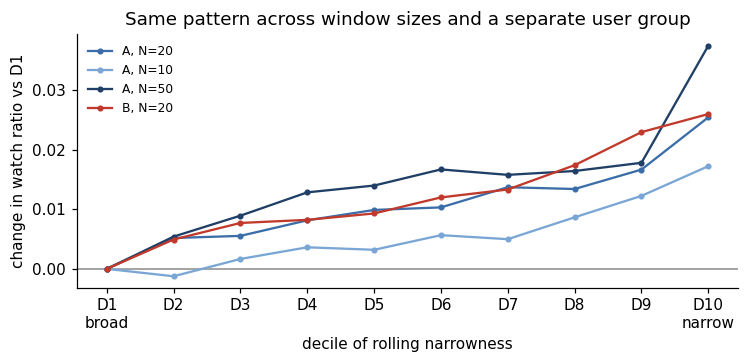

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.axhline(0, color=GREY, lw=1)
for (name, c), col in zip(curves.items(), [BLUE, "#7aa6d6", "#1f3f66", RED]):
    ax.plot(c.index, c.coef, "o-", ms=3, label=name, color=col)
ax.set_xticks(range(1, 11), ["D1\nbroad"] + [f"D{i}" for i in range(2, 10)] + ["D10\nnarrow"])
ax.set(title="Same pattern across window sizes and a separate user group",
       ylabel="change in watch ratio vs D1", xlabel="decile of rolling narrowness")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "02_robustness.png")

## 9. Short term vs next day

Everything above is about the current session. The real worry with narrow feeds is the slower one, where people get bored and come back less. I build a user by day panel. For every day with at least 20 views I compute how narrow that day was, then look at the next day.

Controls are today's views and today's mean watch ratio, so the comparison is between days that were equally busy and equally engaging but differed in variety. Fixed effects are user and calendar day, so a holiday or a platform-wide change cannot drive it.

In [14]:
d = read(["user_id", "day", "ptag", "wr"])
ud = user_day_panel(d)
del d; gc.collect()
print(f"User-days: {len(ud):,}   next-day active rate: {ud.next_active.mean():.1%}")
print("Day narrowness quintile edges:", ud.nar_day.quantile([.2, .4, .6, .8]).round(3).tolist())

ud["qq"] = pd.qcut(ud.nar_day, 5, labels=False)
Q = []
for k in range(1, 5):
    ud[f"q{k}"] = (ud.qq == k).astype(float); Q.append(f"q{k}")
DC = ["log_views", "wr_day"]
day_res = {y: cfeols(f"day_{y}", ud, y, Q + DC, fe=("user_id", "day"))
           for y in ["log_next", "next_active", "log_next3"]}
for y, r in day_res.items():
    print(f"\n{y}   mean {r.attrs['y_mean']:.3f}   n {r.attrs['n']:,}")
    print(r.loc[Q + DC, ["coef", "lo", "hi", "p"]].round(4).to_string())

User-days: 140,101   next-day active rate: 90.3%
Day narrowness quintile edges: [0.23, 0.261, 0.297, 0.349]

log_next   mean 3.611   n 140,101
             coef      lo      hi       p
q1        -0.0037 -0.0263  0.0190  0.7510
q2        -0.0070 -0.0306  0.0165  0.5594
q3        -0.0449 -0.0702 -0.0196  0.0005
q4        -0.0607 -0.0889 -0.0325  0.0000
log_views  0.3686  0.3527  0.3846  0.0000
wr_day    -0.0911 -0.1178 -0.0643  0.0000

next_active   mean 0.903   n 140,101
             coef      lo      hi       p
q1         0.0013 -0.0033  0.0058  0.5874
q2         0.0003 -0.0046  0.0051  0.9100
q3        -0.0069 -0.0122 -0.0016  0.0104
q4        -0.0117 -0.0177 -0.0056  0.0002
log_views  0.0358  0.0327  0.0389  0.0000
wr_day     0.0053 -0.0004  0.0110  0.0672

log_next3   mean 4.530   n 140,099
             coef      lo      hi       p
q1         0.0288  0.0073  0.0503  0.0087
q2         0.0381  0.0157  0.0605  0.0009
q3         0.0160 -0.0081  0.0402  0.1933
q4         0.0100 -0.0169  

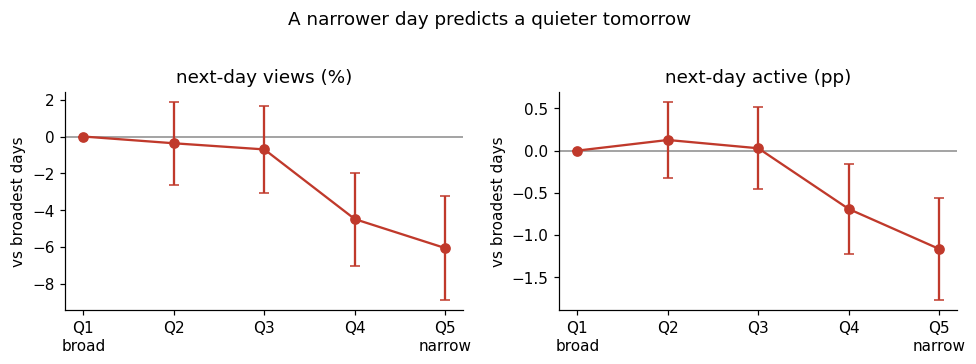

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (y, lab, scale) in zip(axes, [("log_next", "next-day views (%)", 100), ("next_active", "next-day active (pp)", 100)]):
    c = day_res[y].loc[Q, ["coef", "lo", "hi"]] * scale
    c = pd.concat([pd.DataFrame({"coef": [0], "lo": [0], "hi": [0]}), c]).reset_index(drop=True)
    ax.axhline(0, color=GREY, lw=1)
    ax.errorbar(range(5), c.coef, yerr=[c.coef - c.lo, c.hi - c.coef], fmt="o-", color=RED, capsize=3)
    ax.set_xticks(range(5), ["Q1\nbroad", "Q2", "Q3", "Q4", "Q5\nnarrow"])
    ax.set(title=lab, ylabel="vs broadest days")
fig.suptitle("A narrower day predicts a quieter tomorrow", y=1.02)
fig.tight_layout(); fig.savefig(FIG / "02_next_day.png", bbox_inches="tight")

## 10. What this means for the policy

In [16]:
st_wr = r_st_wr.loc[["k4_5", "k6_9"], "coef"]
nd = day_res["log_next"].loc["q4"]
na = day_res["next_active"].loc["q4"]
result = {
    "views": int(totals["views"]), "users": int(totals["users"]), "sessions": int(totals["sessions"]),
    "within_user_var_share": round(float(within_var / total_var), 3),
    "mean_wr_A": round(r_wr.attrs["y_mean"], 4),
    "short_term_wr_D10_vs_D1": round(float(cw.coef.iloc[-1]), 4),
    "short_term_wr_D10_vs_D1_pct": round(float(cw.coef.iloc[-1] / r_wr.attrs["y_mean"] * 100), 2),
    "short_term_exit_D10_vs_D1_pp": round(float(ce.coef.iloc[-1] * 100), 3),
    "exit_base_rate": round(r_exit.attrs["y_mean"], 4),
    "streak_4_5_wr_pct": round(float(st_wr["k4_5"] / r_wr.attrs["y_mean"] * 100), 2),
    "streak_6_9_wr_pct": round(float(st_wr["k6_9"] / r_wr.attrs["y_mean"] * 100), 2),
    "share_views_streak_ge4": round(share_ge4, 4),
    "next_day_views_Q5_vs_Q1_pct": round(float(nd.coef * 100), 2),
    "next_day_views_Q5_ci_pct": [round(float(nd.lo * 100), 2), round(float(nd.hi * 100), 2)],
    "next_day_active_Q5_vs_Q1_pp": round(float(na.coef * 100), 2),
    "next_day_active_base": round(day_res["next_active"].attrs["y_mean"], 4),
    "trigger_narrow_20_p60": round(float(edges.loc[6, "min"]), 3),
    "trigger_streak": 4,
}
(ROOT / "reports" / "phase2_results.json").write_text(json.dumps(result, indent=2))
pd.Series({k: str(v) for k, v in result.items()}).to_frame("value")

,value
views,12530806
users,7176
sessions,101740
within_user_var_share,0.821
mean_wr_A,0.8912
short_term_wr_D10_vs_D1,0.0255
short_term_wr_D10_vs_D1_pct,2.86
short_term_exit_D10_vs_D1_pp,-1.143
exit_base_rate,0.069
streak_4_5_wr_pct,-2.62


## Takeaways

1. **The hypothesis was half wrong, which is the most useful result here.** Inside a session, a narrower recent feed goes with *more* watching and *fewer* exits, monotonically, on two separate user groups and three window sizes. Narrow is not the same as boring, at least not in the moment.
2. **What hurts in the moment is repetition.** Once 4 or more videos in a row share a tag, watch ratio drops, and it drops sharply at 6 to 9. It only affects a small share of views, so it is a targeted problem.
3. **The cost of narrowness shows up the next day.** Days in the narrowest fifth predict fewer views and a lower chance of coming back the next day than equally busy, equally engaging broad days. Over a three day horizon the effect is not clear, so this is a modest effect.
4. **That is the classic exploit trap.** A ranker trained on watch ratio will keep narrowing, because narrowing pays today, while the bill arrives tomorrow. An offline metric that only looks at the session will never see it.

**What changes for Phase 4.** The injection policy gets two triggers instead of one
- **Streak breaker.** If the last 4 videos share a tag, the next slot comes from an adjacent tag
- **Narrowness trigger.** Once rolling narrowness passes the 60th percentile (`trigger_narrow_20_p60`), inject 1–2 adjacent slots per 10

The policies get judged on short-term relevance (which they should cost a little) and on diversity and creator exposure (which they should improve), with the next-day estimate used to put a value on the diversity.

**Caveat.** This is observational. The recommender chose what people saw, and fixed effects remove stable differences between users, videos and days, not moment-to-moment mood. A narrow day might reflect a user who was already drifting away. That is why Phase 4 tests the policies against the fully observed small matrix rather than leaning on these coefficients.